2nd try notebook

We use much more logical approximation, and use 3 inputs only, with data cleaning

*create dataset from average data excel*

In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np

# load spatial data
df_coords = pd.read_csv('coordinates.csv')

points = gpd.GeoDataFrame(
    df_coords, 
    geometry=gpd.points_from_xy(df_coords['Long'], df_coords['Lat']),
    crs="EPSG:4326"
)

lu_mangrove = gpd.read_file('aoi/LU_mangrove_forest_61.shp')
province = gpd.read_file('province/province.shp')

target_crs = "EPSG:32647"
points = points.to_crs(target_crs)
lu_mangrove = lu_mangrove.to_crs(target_crs)
province = province.to_crs(target_crs)


# data joining from coordinates and provinces
mangrove_points = gpd.sjoin(points, lu_mangrove, how="inner", predicate="intersects")

if 'index_right' in mangrove_points.columns:
    mangrove_points = mangrove_points.drop(columns=['index_right'])
if 'index_left' in mangrove_points.columns:
    mangrove_points = mangrove_points.drop(columns=['index_left'])

final_points = gpd.sjoin(mangrove_points, province, how="inner", predicate="intersects")
final_points = final_points.rename(columns={'PROV_NAM_E': 'Province'}) 
final_points['Province'] = final_points['Province'].str.replace('Changwat ', '', regex=False).str.strip()


# data processing from PSU's data
df_excel = pd.read_excel('Detail1.xlsx')
prov_data = df_excel.iloc[7:12].copy()
prov_data.columns = ['Province', 'Species', 'Area_Rai', 'Density_per_Rai', 'Prov_DBH_cm', 'Height_m', 'Outstanding']
prov_data = prov_data.dropna(subset=['Province'])
prov_data['Province'] = prov_data['Province'].str.strip()

for col in ['Area_Rai', 'Density_per_Rai', 'Prov_DBH_cm', 'Height_m']:
    prov_data[col] = pd.to_numeric(prov_data[col], errors='coerce')

prov_data['Prov_DBH_cm'] = prov_data['Prov_DBH_cm'].fillna(prov_data['Prov_DBH_cm'].mean())
prov_data['Height_m'] = prov_data['Height_m'].fillna(prov_data['Height_m'].mean())


# data merge
df_merged = pd.merge(final_points, prov_data[['Province', 'Density_per_Rai', 'Prov_DBH_cm']], on='Province', how='inner')

pixel_area = 100 
rai_area = 1600
df_merged['Base_Trees_Pixel'] = (pixel_area / rai_area) * df_merged['Density_per_Rai']

if 'NDVI' in df_merged.columns:
    df_merged['NDVI_Mean'] = df_merged.groupby('Province')['NDVI'].transform('mean')
    df_merged['NDVI_Std'] = df_merged.groupby('Province')['NDVI'].transform('std')
    df_merged['NDVI_Zscore'] = (df_merged['NDVI'] - df_merged['NDVI_Mean']) / df_merged['NDVI_Std']
    
    df_merged['Point_Trees'] = (df_merged['Base_Trees_Pixel'] * (1 + (0.40 * df_merged['NDVI_Zscore']))).clip(lower=1)
    df_merged['Point_DBH'] = (df_merged['Prov_DBH_cm'] * (1 + (0.15 * df_merged['NDVI_Zscore']))).clip(lower=1)
else:
    np.random.seed(42) 
    df_merged['Point_Trees'] = np.random.normal(df_merged['Base_Trees_Pixel'], df_merged['Base_Trees_Pixel'] * 0.2).clip(min=1)
    df_merged['Point_DBH'] = np.random.normal(df_merged['Prov_DBH_cm'], df_merged['Prov_DBH_cm'] * 0.1).clip(min=1)


# calculate agb
wood_density = 0.69 
df_merged['AGB_per_Tree_kg'] = 0.251 * wood_density * (df_merged['Point_DBH'] ** 2.46)
df_merged['Total_AGB_kg'] = df_merged['AGB_per_Tree_kg'] * df_merged['Point_Trees']


# cleaning and exporting the data
df_cleaned = pd.DataFrame(df_merged[['Lat', 'Long', 'Total_AGB_kg']])
print(df_cleaned.head())

df_cleaned.to_csv('cleaned_agb_coordinates.csv', index=False)

       Lat       Long  Total_AGB_kg
0  10.3115  98.752899   1307.020789
1  10.3015  98.759598    908.896156
2  10.2920  98.753601   1867.578748
3  10.3224  98.771301   1731.698104
4  10.2412  98.722702    849.359355


*get satellite data*

In [ ]:
import pandas as pd
import geopandas as gpd
import ee
import json

ee.Authenticate()
ee.Initialize(project='ee-raditiaoffice') 

province_gpd = gpd.read_file('province/province.shp').to_crs('EPSG:4326')

# convert geodataframe to ee.Geometry
geojson_dict = json.loads(province_gpd.to_json())
roi_province = ee.FeatureCollection(geojson_dict).geometry()

# load processed coordinates data
df_coords = pd.read_csv('cleaned_agb_coordinates.csv')

features = []
for index, row in df_coords.iterrows():
    geom = ee.Geometry.Point([row['Long'], row['Lat']])
    feat = ee.Feature(geom, {'Total_AGB_kg': row['Total_AGB_kg']})
    features.append(feat)

fc_points = ee.FeatureCollection(features)

start_date = '2026-03-01'
end_date = '2026-03-31'

# get sentinel 2 data
def mask_s2_clouds(image):
    qa = image.select('QA60')
    cloudBitMask = 1 << 10
    cirrusBitMask = 1 << 11
    mask = qa.bitwiseAnd(cloudBitMask).eq(0).And(qa.bitwiseAnd(cirrusBitMask).eq(0))
    return image.updateMask(mask).divide(10000)

s2_collection = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
    .filterBounds(roi_province) \
    .filterDate(start_date, end_date) \
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)) \
    .map(mask_s2_clouds)

s2_median = s2_collection.median()
s2_bands = s2_median.select(['B4', 'B3', 'B2', 'B8']).rename(['Red', 'Green', 'Blue', 'NIR'])
ndvi = s2_median.normalizedDifference(['B8', 'B4']).rename('NDVI')

# combine and cut s2 image to the province shape
s2_combined = s2_bands.addBands(ndvi).clip(roi_province)

# get sentinel 1 data (VV, VH)
s1_collection = ee.ImageCollection('COPERNICUS/S1_GRD') \
    .filterBounds(roi_province) \
    .filterDate(start_date, end_date) \
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')) \
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')) \
    .filter(ee.Filter.eq('instrumentMode', 'IW'))

# get median and cut s1 image to the province
s1_median = s1_collection.select(['VV', 'VH']).median().clip(roi_province)

# combine and extract values to csv
combined_image = s2_combined.addBands(s1_median)

sampled_data = combined_image.reduceRegions(
    collection=fc_points,
    reducer=ee.Reducer.first(),
    scale=10 
)

extracted_features = sampled_data.getInfo()['features']

extracted_list = []
for feat in extracted_features:
    props = feat['properties']
    if 'Red' in props and 'VV' in props:
        props['Long'] = feat['geometry']['coordinates'][0]
        props['Lat'] = feat['geometry']['coordinates'][1]
        extracted_list.append(props)

df_final_ml = pd.DataFrame(extracted_list)
df_final_ml = df_final_ml.dropna(subset=['Red', 'Green', 'Blue', 'NIR', 'NDVI', 'VV', 'VH'])
df_final_ml = df_final_ml[['Lat', 'Long', 'Total_AGB_kg', 'Red', 'Green', 'Blue', 'NIR', 'NDVI', 'VV', 'VH']]

print(f"Total valid points: {len(df_final_ml)}")
df_final_ml.to_csv('final_training_data_agb.csv', index=False)

# exporting tiff to google drive
print("sending s2 task to gee")
task_s2 = ee.batch.Export.image.toDrive(
    image=s2_combined,
    description='Export_Sentinel2_Province',
    folder='GEE_Mangrove_Export',
    fileNamePrefix='Sentinel2_Optical_NDVI',
    region=roi_province,
    scale=10, 
    crs='EPSG:32647',
    maxPixels=1e13
)
task_s2.start()

print("sending s1 task to gee")
task_s1 = ee.batch.Export.image.toDrive(
    image=s1_median,
    description='Export_Sentinel1_Province',
    folder='GEE_Mangrove_Export',
    fileNamePrefix='Sentinel1_SAR',
    region=roi_province,
    scale=10,
    crs='EPSG:32647',
    maxPixels=1e13
)
task_s1.start()

print("success")

*clean the data*

In [ ]:
import pandas as pd

# Load data
df = pd.read_csv('final_training_data_agb.csv')

# delete not vegetation points
df_clean = df[df['NDVI'] >= 0.3].copy()

# delete extreme outlier VV and VH
df_clean = df_clean[df_clean['VH'] >= -22].copy()

print(f"before : {len(df)} points")
print(f"after : {len(df_clean)} points")

# save data
df_clean.to_csv('cleaned_training_data.csv', index=False)

Data awal: 492 titik
Setelah cleaning NDVI & Air: 491 titik


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import rankdata

df = pd.read_csv('cleaned_training_data.csv')

# count the Z-Score (standarization) for satellite
z_ndvi = (df['NDVI'] - df['NDVI'].mean()) / df['NDVI'].std()
z_vv = (df['VV'] - df['VV'].mean()) / df['VV'].std()
z_vh = (df['VH'] - df['VH'].mean()) / df['VH'].std()

# make weighted ndvi, with vv and vh support
np.random.seed(42)
natural_noise = np.random.normal(0, 1.0, len(df)) 
# 60% optical effect, 40% radar effect, with additional 20% natural noise
composite_index = (0.6 * z_ndvi) + (0.2 * z_vv) + (0.2 * z_vh) + (0.2 * natural_noise)

# re-distribution agb based on the composite rank
df['Rank_Composite'] = rankdata(composite_index)
sorted_agb = df['Total_AGB_kg'].sort_values().values # take real value and sort

agb_indices = (df['Rank_Composite'] - 1).astype(int)
df['AGB_Revised_kg'] = sorted_agb[agb_indices]

# correlation check
print("=== Feature Correlation vs Target AGB ===")
print(df[['AGB_Revised_kg', 'NDVI', 'VV', 'VH']].corr()['AGB_Revised_kg'])

df.to_csv('final_ml_ready.csv', index=False)

=== Korelasi Fitur vs Target AGB ===
AGB_Revised_kg    1.000000
NDVI              0.503948
VV                0.491823
VH                0.483165
Name: AGB_Revised_kg, dtype: float64


*modelling*

try finding the best one in 1 code (separated by each folder)

In [ ]:
import pandas as pd
import numpy as np
import time
import joblib 
import os
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
import xgboost as xgb
import lightgbm as lgb
import warnings
warnings.filterwarnings('ignore')

# load data
df = pd.read_csv('final_ml_ready.csv')
X = df[['VV', 'VH', 'NDVI']]
y = df['AGB_Revised_kg']

# model setup and parameter grid
models_params = {
    'Extra Trees': {'model': ExtraTreesRegressor(random_state=42), 'params': {'n_estimators': [100, 300, 500, 800], 'max_depth': [None, 10, 20, 30, 50], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4], 'max_features': ['sqrt', 'log2', 1.0]}},
    'XGBoost': {'model': xgb.XGBRegressor(objective='reg:squarederror', random_state=42), 'params': {'n_estimators': [100, 300, 500], 'learning_rate': [0.01, 0.05, 0.1], 'max_depth': [3, 5, 7, 9], 'subsample': [0.6, 0.8, 1.0], 'colsample_bytree': [0.6, 0.8, 1.0]}},
    'Gradient Boosting': {'model': GradientBoostingRegressor(random_state=42), 'params': {'n_estimators': [100, 300, 500], 'learning_rate': [0.01, 0.05, 0.1], 'max_depth': [3, 5, 7], 'subsample': [0.7, 0.8, 1.0], 'min_samples_split': [2, 5, 10]}},
    'Random Forest': {'model': RandomForestRegressor(random_state=42), 'params': {'n_estimators': [100, 300, 500], 'max_depth': [None, 10, 20, 30], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4], 'max_features': ['sqrt', 'log2', 1.0]}},
    'LightGBM': {'model': lgb.LGBMRegressor(random_state=42, verbose=-1), 'params': {'n_estimators': [100, 300, 500], 'learning_rate': [0.01, 0.05, 0.1], 'max_depth': [-1, 5, 10, 20], 'num_leaves': [31, 50, 100], 'subsample': [0.7, 0.8, 1.0], 'colsample_bytree': [0.7, 0.8, 1.0]}}
}

# tuning and searching optimal parameter automatically
test_ratios = [0.15, 0.20, 0.25, 0.30, 0.35]
all_results = []

# dictionary to find the best algorithm
best_per_algo = {name: {'r2': -np.inf, 'model': None, 'test_size': None} for name in models_params.keys()}

print("starting hyperparameter tuning")
for ratio in test_ratios:
    print(f"\n--- Testing Test Size: {ratio*100}% ---")
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=ratio, random_state=42)
    
    for name, mp in models_params.items():
        search = RandomizedSearchCV(estimator=mp['model'], param_distributions=mp['params'], n_iter=30, cv=5, scoring='r2', n_jobs=-1, random_state=42, verbose=0)
        search.fit(X_train, y_train)
        
        current_best_model = search.best_estimator_
        y_pred = current_best_model.predict(X_test)
        
        r2 = r2_score(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        
        all_results.append({'Test_Size': ratio, 'Model': name, 'R2_Score': r2, 'RMSE': rmse, 'Best_Params': search.best_params_})
        print(f"[{name}] R2: {r2:.4f} | RMSE: {rmse:.2f}")
        
        # save is this the best algorithm
        if r2 > best_per_algo[name]['r2']:
            best_per_algo[name]['r2'] = r2
            best_per_algo[name]['model'] = current_best_model
            best_per_algo[name]['test_size'] = ratio

# save model to respected folder
print("saving model to the respected folder")
for algo_name, info in best_per_algo.items():
    folder_name = algo_name.replace(" ", "_") # change space to "_"
    os.makedirs(folder_name, exist_ok=True)
    model_path = os.path.join(folder_name, 'best_model.pkl')
    
    joblib.dump(info['model'], model_path)
    print(f"-> {algo_name} (R2: {info['r2']:.4f}) disimpan di '{model_path}'")

results_df = pd.DataFrame(all_results).sort_values(by='R2_Score', ascending=False).reset_index(drop=True)
results_df.to_csv('massive_tuning_results.csv', index=False)

=== Memulai Massive Hyperparameter Tuning ===

--- Menguji Test Size: 15.0% ---
[Extra Trees] R2: 0.7738 | RMSE: 403.67
[XGBoost] R2: 0.7606 | RMSE: 415.29
[Gradient Boosting] R2: 0.7709 | RMSE: 406.30
[Random Forest] R2: 0.7602 | RMSE: 415.65
[LightGBM] R2: 0.7474 | RMSE: 426.58

--- Menguji Test Size: 20.0% ---
[Extra Trees] R2: 0.7392 | RMSE: 439.94
[XGBoost] R2: 0.7004 | RMSE: 471.55
[Gradient Boosting] R2: 0.7262 | RMSE: 450.75
[Random Forest] R2: 0.7175 | RMSE: 457.87
[LightGBM] R2: 0.6671 | RMSE: 497.04

--- Menguji Test Size: 25.0% ---
[Extra Trees] R2: 0.7656 | RMSE: 429.38
[XGBoost] R2: 0.7432 | RMSE: 449.42
[Gradient Boosting] R2: 0.7596 | RMSE: 434.84
[Random Forest] R2: 0.7454 | RMSE: 447.44
[LightGBM] R2: 0.7398 | RMSE: 452.33

--- Menguji Test Size: 30.0% ---
[Extra Trees] R2: 0.7857 | RMSE: 413.77
[XGBoost] R2: 0.7554 | RMSE: 442.09
[Gradient Boosting] R2: 0.7808 | RMSE: 418.51
[Random Forest] R2: 0.7591 | RMSE: 438.67
[LightGBM] R2: 0.7525 | RMSE: 444.65

--- Menguji T

visualization of evaluation

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import pearsonr
import numpy as np
import pandas as pd
import joblib

df = pd.read_csv('final_ml_ready.csv')
df_results = pd.read_csv('massive_tuning_results.csv')

features = ['VV', 'VH', 'NDVI']
X = df[features]
y = df['AGB_Revised_kg']
n_total = len(df)

algorithms = ['Extra Trees', 'XGBoost', 'Gradient Boosting', 'Random Forest', 'LightGBM']
sns.set_theme(style="whitegrid")

for algo in algorithms:
    folder_name = algo.replace(" ", "_")
    model_path = f"{folder_name}/best_model.pkl"
    
    # skip is this folder not formed
    if not os.path.exists(model_path):
        continue
        
    print(f"making visualization of {algo}...")
    best_model = joblib.load(model_path)
    
    # find the best test size ratio to each algorithm from csv
    best_ratio = df_results[df_results['Model'] == algo].sort_values(by='R2_Score', ascending=False).iloc[0]['Test_Size']
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=best_ratio, random_state=42)
    best_model.fit(X_train, y_train)
    y_pred = best_model.predict(X_test)
    
    n_test = len(y_test)
    r2_val = r2_score(y_test, y_pred)
    rmse_val = np.sqrt(mean_squared_error(y_test, y_pred))

    # performance plot
    fig = plt.figure(figsize=(18, 5))
    
    ax1 = plt.subplot(1, 3, 1)
    sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color='teal')
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    plt.title(f'Actual vs Predicted AGB\n({algo})', fontweight='bold')
    plt.xlabel('Actual AGB (kg)')
    plt.ylabel('Predicted AGB (kg)')
    text_str = f'N = {n_test}\n$R^2$ = {r2_val:.4f}\nRMSE = {rmse_val:.2f} kg'
    ax1.text(0.05, 0.95, text_str, transform=ax1.transAxes, fontsize=11, verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray'))

    plt.subplot(1, 3, 2)
    try:
        importances = pd.Series(best_model.feature_importances_, index=features).sort_values(ascending=False)
        sns.barplot(x=importances.values, y=importances.index, palette='viridis', hue=importances.index, legend=False)
        plt.title(f'Feature Importance Score\n({algo})', fontweight='bold')
        plt.xlabel('Importance')
    except AttributeError:
        plt.text(0.5, 0.5, 'Feature Importance Not Available', ha='center', va='center', fontsize=12)

    plt.subplot(1, 3, 3)
    corr_matrix = df[features + ['AGB_Revised_kg']].corr()
    sns.heatmap(corr_matrix[['AGB_Revised_kg']].drop('AGB_Revised_kg').sort_values(by='AGB_Revised_kg', ascending=False), annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.3f')
    plt.title('Correlation with AGB_Revised', fontweight='bold')

    plt.tight_layout()
    plt.savefig(f"{folder_name}/Plot_Performance_{folder_name}.png")
    plt.close()
    print(f"-> Grafik performa disimpan di folder {folder_name}/")

Membuat visualisasi untuk: Extra Trees...
-> Grafik performa disimpan di folder Extra_Trees/
Membuat visualisasi untuk: XGBoost...
-> Grafik performa disimpan di folder XGBoost/
Membuat visualisasi untuk: Gradient Boosting...
-> Grafik performa disimpan di folder Gradient_Boosting/
Membuat visualisasi untuk: Random Forest...
-> Grafik performa disimpan di folder Random_Forest/
Membuat visualisasi untuk: LightGBM...
-> Grafik performa disimpan di folder LightGBM/


visualization of algorithm's comparison

C:\Users\nexus2019\AppData\Local\Temp\ipykernel_16696\371326667.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(data=max_r2_df, x='Model', y='R2_Score', palette='viridis', ax=axes[1])
C:\Users\nexus2019\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


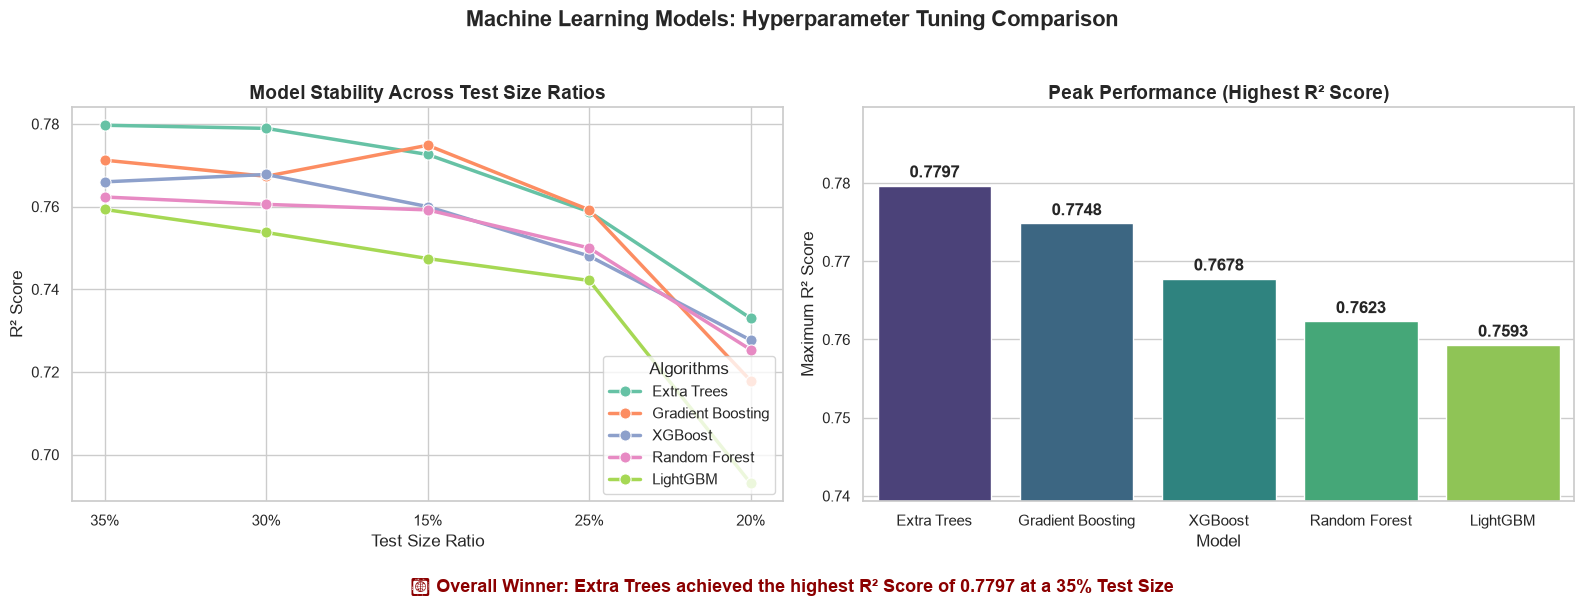

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the tuning results data
df = pd.read_csv('massive_tuning_results.csv')

# Format Test_Size to a percentage string for cleaner X-axis labels
df['Test_Size_Pct'] = (df['Test_Size'] * 100).astype(int).astype(str) + '%'

# Identify the overall best model
best_row = df.loc[df['R2_Score'].idxmax()]
best_model = best_row['Model']
best_r2 = best_row['R2_Score']
best_test_size = best_row['Test_Size_Pct']

# 2. Configure visualization style
sns.set_theme(style="whitegrid", palette="Set2")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Machine Learning Models: Hyperparameter Tuning Comparison', fontsize=16, fontweight='bold')

# ==========================================
# PLOT 1: R2 Score vs Test Size (Line Plot)
# ==========================================
sns.lineplot(data=df, x='Test_Size_Pct', y='R2_Score', hue='Model', 
             marker='o', linewidth=2.5, markersize=8, ax=axes[0])
axes[0].set_title('Model Stability Across Test Size Ratios', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Test Size Ratio', fontsize=12)
axes[0].set_ylabel('R² Score', fontsize=12)
axes[0].legend(title='Algorithms', loc='lower right')

# ==========================================
# PLOT 2: Best R2 Score per Model (Bar Chart)
# ==========================================
# Extract the maximum R2 score for each model
max_r2_df = df.groupby('Model')['R2_Score'].max().reset_index().sort_values(by='R2_Score', ascending=False)

barplot = sns.barplot(data=max_r2_df, x='Model', y='R2_Score', palette='viridis', ax=axes[1])
axes[1].set_title('Peak Performance (Highest R² Score)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Model', fontsize=12)
axes[1].set_ylabel('Maximum R² Score', fontsize=12)

# Dynamically set y-axis limits to zoom in on the differences
min_r2 = max_r2_df['R2_Score'].min()
max_r2 = max_r2_df['R2_Score'].max()
axes[1].set_ylim(min_r2 - 0.02, max_r2 + 0.01) 

# Add data labels on top of the bars
for p in barplot.patches:
    barplot.annotate(format(p.get_height(), '.4f'), 
                     (p.get_x() + p.get_width() / 2., p.get_height()), 
                     ha='center', va='center', 
                     xytext=(0, 9), 
                     textcoords='offset points',
                     fontweight='bold')

# ==========================================
# ANNOTATION & DISPLAY
# ==========================================
# Add a prominent text highlighting the best model at the bottom
plt.figtext(0.5, 0.01, f"🏆 Overall Winner: {best_model} achieved the highest R² Score of {best_r2:.4f} at a {best_test_size} Test Size", 
            ha="center", fontsize=13, fontweight='bold', color='darkred')

# Adjust layout to prevent overlapping text
plt.tight_layout(rect=[0, 0.05, 1, 0.95]) 
plt.show()

*mapping*


In [ ]:
import ee
import geopandas as gpd
import rasterio
from rasterio.mask import mask
from rasterio.merge import merge
import numpy as np
import joblib
import requests
import json
import os

# choose the algorithm
TARGET_ALGO = "XGBoost"

ee.Authenticate()
ee.Initialize(project='ee-raditiaoffice')

print(f"loading model from {TARGET_ALGO}...")
model_path = f"{TARGET_ALGO}/best_model.pkl"
local_model = joblib.load(model_path)

gdf = gpd.read_file('./province/province.shp').to_crs("EPSG:4326")
gdf = gdf.dissolve(by='PROV_NAM_E').reset_index()

START_DATE = '2026-03-01'
END_DATE = '2026-03-31'

# main loop for each province
for idx, row in gdf.iterrows():
    prov_name = str(row.get('PROV_NAM_E', f'Province_{idx}')).replace("Changwat ", "").strip()
    print(f"\n==========================================")
    print(f"processing province {prov_name} (Model: {TARGET_ALGO})")
    
    geom_json = json.loads(gpd.GeoSeries([row['geometry']]).to_json())['features'][0]['geometry']
    province_poly = ee.Geometry(geom_json)
    
    minx, miny, maxx, maxy = row['geometry'].bounds
    grid_size = 0.1  
    x_coords = np.arange(minx, maxx, grid_size)
    y_coords = np.arange(miny, maxy, grid_size)
    
    tile_files = []
    tile_counter = 0
    
    for x in x_coords:
        for y in y_coords:
            tile_geom = ee.Geometry.Rectangle([x, y, x + grid_size, y + grid_size])
            intersection = tile_geom.intersection(province_poly, ee.ErrorMargin(1))
            
            try:
                s1 = ee.ImageCollection('COPERNICUS/S1_GRD').filterBounds(tile_geom).filterDate(START_DATE, END_DATE).filter(ee.Filter.eq('instrumentMode', 'IW')).filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV')).filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')).select(['VV', 'VH']).median()
                
                def mask_s2_clouds(image):
                    qa = image.select('QA60')
                    return image.updateMask(qa.bitwiseAnd(1<<10).eq(0).And(qa.bitwiseAnd(1<<11).eq(0))).divide(10000)

                s2_collection = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED').filterBounds(tile_geom).filterDate(START_DATE, END_DATE).filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 30)).map(mask_s2_clouds)
                ndvi = s2_collection.median().normalizedDifference(['B8', 'B4']).rename('NDVI')
                
                img_tile = s1.addBands(ndvi).select(['VV', 'VH', 'NDVI']).clip(intersection)
                
                temp_tif = f"temp_{prov_name}_{tile_counter}.tif"
                pred_tif = f"pred_{prov_name}_{tile_counter}.tif"
                
                url = img_tile.getDownloadUrl({'scale': 10, 'crs': 'EPSG:4326', 'region': tile_geom, 'format': 'GEO_TIFF'})
                res = requests.get(url)
                if res.status_code == 200 and len(res.content) > 1000:
                    with open(temp_tif, 'wb') as f:
                        f.write(res.content)
                        
                    with rasterio.open(temp_tif) as src:
                        profile = src.profile
                        profile.update(count=1, dtype=rasterio.float32, nodata=-9999)
                        img_data = src.read()
                        c, h, w = img_data.shape
                        
                        img_2d = img_data.transpose(1, 2, 0).reshape(-1, c)
                        valid_mask = np.any(img_2d != 0, axis=1)
                        pred_2d = np.full(img_2d.shape[0], -9999, dtype=np.float32)
                        
                        if np.any(valid_mask):
                            valid_pixels = np.nan_to_num(img_2d[valid_mask])
                            pred_2d[valid_mask] = local_model.predict(valid_pixels)
                        
                        agb_block = pred_2d.reshape(1, h, w)
                        with rasterio.open(pred_tif, 'w', **profile) as dst:
                            dst.write(agb_block)
                            
                    tile_files.append(pred_tif)
                    tile_counter += 1
                
                if os.path.exists(temp_tif): os.remove(temp_tif)
            except Exception as e:
                continue
                
    if tile_files:
        src_files_to_mosaic = [rasterio.open(tf) for tf in tile_files]
        mosaic, out_trans = merge(src_files_to_mosaic)
        
        out_meta = src_files_to_mosaic[0].meta.copy()
        out_meta.update({"height": mosaic.shape[1], "width": mosaic.shape[2], "transform": out_trans, "crs": "EPSG:4326", "nodata": -9999})
        
        output_final = os.path.join(TARGET_ALGO, f"AGB_Map_{prov_name}.tif")
        with rasterio.open(output_final, "w", **out_meta) as dest:
            dest.write(mosaic)
            
        for src in src_files_to_mosaic: src.close()
        for tf in tile_files:
            if os.path.exists(tf): os.remove(tf)
                
        print(f"success. saved in {output_final}")

Memuat model lokal dari folder XGBoost...

Memproses Provinsi: Krabi (Model: XGBoost)
SUKSES: Peta final tersimpan -> XGBoost\AGB_Map_Krabi.tif

Memproses Provinsi: Phang Nga (Model: XGBoost)
SUKSES: Peta final tersimpan -> XGBoost\AGB_Map_Phang Nga.tif

Memproses Provinsi: Ranong (Model: XGBoost)
SUKSES: Peta final tersimpan -> XGBoost\AGB_Map_Ranong.tif

Memproses Provinsi: Satun (Model: XGBoost)
SUKSES: Peta final tersimpan -> XGBoost\AGB_Map_Satun.tif

Memproses Provinsi: Trang (Model: XGBoost)
SUKSES: Peta final tersimpan -> XGBoost\AGB_Map_Trang.tif


In [8]:
import geopandas as gpd
import rasterio
from rasterio.mask import mask
import os

# 1. Buka Shapefile Provinsi
print("Memuat shapefile provinsi...")
gdf = gpd.read_file('./province/province.shp')
gdf = gdf.to_crs("EPSG:4326")

# Satukan semua poligon per provinsi menjadi MultiPolygon berdasarkan kolom PROV_NAM_E
gdf = gdf.dissolve(by='PROV_NAM_E').reset_index()

# 2. Daftar provinsi dan folder algoritma sesuai struktur direktori Anda
provinces = ['Krabi', 'Phang Nga', 'Ranong', 'Satun', 'Trang']
algorithms = ['Gradient_Boosting', 'LightGBM', 'Random_Forest', 'XGBoost']

print("\nMemulai proses clipping secara massal untuk semua algoritma...")

for algo in algorithms:
    print(f"\n=== Memproses Folder Algoritma: {algo} ===")
    
    # Cek apakah folder algoritma ada
    if not os.path.exists(algo):
        print(f"Folder '{algo}' tidak ditemukan. Melewati algoritma ini...")
        continue
        
    for prov in provinces:
        # Mengarahkan path I/O langsung ke dalam folder masing-masing algoritma
        input_tif = os.path.join(algo, f"AGB_Map_{prov}.tif")
        output_tif = os.path.join(algo, f"AGB_Map_{prov}_Clipped.tif")
        
        if not os.path.exists(input_tif):
            print(f"  [SKIP] File {input_tif} belum ada.")
            continue
            
        print(f"  -> Memotong peta {prov}...")
        
        # Ekstrak geometri. Penggunaan str.contains akan otomatis menoleransi awalan "Changwat "
        geom = gdf[gdf['PROV_NAM_E'].str.contains(prov, case=False, na=False)]['geometry'].values
        
        if len(geom) == 0:
            print(f"  [ERROR] Geometri untuk {prov} tidak ditemukan di shapefile.")
            continue
            
        try:
            with rasterio.open(input_tif) as src:
                # Memotong raster. Piksel kotak hitam di luar poligon diset ke -9999
                out_image, out_transform = mask(src, geom, crop=True, nodata=-9999)
                out_meta = src.meta.copy()
                
                # Update metadata agar latar belakang di-render transparan (NoData)
                out_meta.update({
                    "driver": "GTiff",
                    "height": out_image.shape[1],
                    "width": out_image.shape[2],
                    "transform": out_transform,
                    "nodata": -9999
                })
                
                # Simpan hasil potongan yang bersih kembali ke folder algoritma yang sama
                with rasterio.open(output_tif, "w", **out_meta) as dest:
                    dest.write(out_image)
                    
            print(f"  [SUKSES] Tersimpan: {output_tif}")
            
        except MemoryError:
            print(f"  [GAGAL] Memori Penuh (RAM) saat memproses {prov}.")
        except Exception as e:
            print(f"  [GAGAL] Error tidak terduga pada {prov}: {e}")

print("\nPROSES CLIPPING UNTUK SELURUH FOLDER SELESAI!")

Memuat shapefile provinsi...

Memulai proses clipping secara massal untuk semua algoritma...

=== Memproses Folder Algoritma: Gradient_Boosting ===
  -> Memotong peta Krabi...
  [SUKSES] Tersimpan: Gradient_Boosting\AGB_Map_Krabi_Clipped.tif
  -> Memotong peta Phang Nga...
  [SUKSES] Tersimpan: Gradient_Boosting\AGB_Map_Phang Nga_Clipped.tif
  -> Memotong peta Ranong...
  [SUKSES] Tersimpan: Gradient_Boosting\AGB_Map_Ranong_Clipped.tif
  -> Memotong peta Satun...
  [SUKSES] Tersimpan: Gradient_Boosting\AGB_Map_Satun_Clipped.tif
  -> Memotong peta Trang...
  [SUKSES] Tersimpan: Gradient_Boosting\AGB_Map_Trang_Clipped.tif

=== Memproses Folder Algoritma: LightGBM ===
  -> Memotong peta Krabi...
  [SUKSES] Tersimpan: LightGBM\AGB_Map_Krabi_Clipped.tif
  -> Memotong peta Phang Nga...
  [SUKSES] Tersimpan: LightGBM\AGB_Map_Phang Nga_Clipped.tif
  -> Memotong peta Ranong...
  [SUKSES] Tersimpan: LightGBM\AGB_Map_Ranong_Clipped.tif
  -> Memotong peta Satun...
  [SUKSES] Tersimpan: LightGBM\AG